## `The operations for a stronger Deep Learning pipeline flow:`
- 1️⃣ `Importing Dependencies`
- 2️⃣ `Loading the Dataset`
- 3️⃣ `Exploratory Data Analysis (EDA)`
- 4️⃣ `Feature Engineering`
- 5️⃣ `Data Preprocessing / Transformation`
- 6️⃣ `Data Visualization (Optional / during or after EDA)`
- 7️⃣ `Splitting the Data`
- 8️⃣ `Building the DL Model`
- 9️⃣ `Evaluation`

 ## `Importing Dependencies`

In [85]:
## Most Important
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data & System
import os

## Preprocessing
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

## Model Selection
from sklearn.model_selection import train_test_split, cross_val_score

## Metrics
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

## Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

## Visualization (Model)
from sklearn.tree import plot_tree

## Pipeline
from sklearn.pipeline import Pipeline

## `Loading the Dataset`

In [86]:
DATASET = '/content/dataset'
OUTPUT = '/content/output'
VISUALISASI = '/content/output/visual'
for d in [DATASET, OUTPUT, VISUALISASI]:
  os.makedirs(d, exist_ok=True)
print('directory berhasil dibuat')

df = pd.read_csv('/kaggle/input/datasets/shaaz74/fatty-liver-progression-dataset-with-biomarkers/fatty_liver_dataset_10k.csv')

directory berhasil dibuat


## `EXPLORATORY DATA ANALYSIS(EDA)`

#### `INFO DATASET

In [87]:
df.head()

,id,age,gender,bmi,alcohol_status,smoking_status,alt,ast,ggt,bilirubin_total,...,hdl_cholestrol,ldl_cholestrol,platelet_count,fasting_blood_sugar,tsh,diabetes_type_2,hypertension,pcos,fatty_liver_grade,liver_cirrhosis
0,1,20,M,25.1,0.0,0.0,228.0,94.0,69.0,0.7,...,49.0,175.0,136,88.0,2.9,0.0,0.0,NaN,2,0
1,2,21,M,23.4,0.0,0.0,156.0,65.0,51.0,1.3,...,51.0,164.0,144,92.0,3.6,0.0,0.0,NaN,1,0
2,3,23,M,21.8,0.0,0.0,28.0,25.0,39.0,1.1,...,46.0,137.0,182,76.0,1.5,0.0,0.0,NaN,0,0
3,4,34,M,25.0,1.0,0.0,81.9,102.9,385.3,1.1,...,34.3,66.6,158,159.0,3.7,1.0,0.0,NaN,3,0
4,5,62,M,21.9,1.0,0.0,42.3,27.9,57.8,1.8,...,27.9,127.1,206,71.7,3.5,0.0,0.0,NaN,1,0


In [88]:
df.tail()

,id,age,gender,bmi,alcohol_status,smoking_status,alt,ast,ggt,bilirubin_total,...,hdl_cholestrol,ldl_cholestrol,platelet_count,fasting_blood_sugar,tsh,diabetes_type_2,hypertension,pcos,fatty_liver_grade,liver_cirrhosis
9995,9996,44,M,28.4,0.0,0.0,45.3,22.4,44.2,0.9,...,51.8,166.7,145,114.7,4.7,NaN,0.0,NaN,1,0
9996,9997,67,M,22.8,0.0,0.0,19.1,34.3,19.0,0.4,...,44.3,43.1,365,60.0,1.5,0.0,0.0,NaN,0,0
9997,9998,20,M,23.1,0.0,0.0,16.4,24.3,21.1,0.6,...,43.1,73.9,187,155.5,1.6,NaN,1.0,NaN,0,0
9998,9999,72,M,35.7,0.0,0.0,40.3,20.4,85.4,0.9,...,39.6,165.6,243,100.3,3.1,0.0,1.0,NaN,2,0
9999,10000,22,F,30.0,0.0,0.0,64.0,95.1,49.7,0.5,...,88.4,102.7,171,69.9,3.9,0.0,0.0,0.0,2,0


In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   10000 non-null  int64  
 1   age                  10000 non-null  int64  
 2   gender               10000 non-null  object 
 3   bmi                  10000 non-null  float64
 4   alcohol_status       9704 non-null   float64
 5   smoking_status       8334 non-null   float64
 6   alt                  10000 non-null  float64
 7   ast                  10000 non-null  float64
 8   ggt                  10000 non-null  float64
 9   bilirubin_total      10000 non-null  float64
 10  triglycerides        10000 non-null  float64
 11  hdl_cholestrol       10000 non-null  float64
 12  ldl_cholestrol       10000 non-null  float64
 13  platelet_count       10000 non-null  int64  
 14  fasting_blood_sugar  10000 non-null  float64
 15  tsh                  10000 non-null  

In [90]:
df.describe()

,id,age,bmi,alcohol_status,smoking_status,alt,ast,ggt,bilirubin_total,triglycerides,hdl_cholestrol,ldl_cholestrol,platelet_count,fasting_blood_sugar,tsh,diabetes_type_2,hypertension,pcos,fatty_liver_grade,liver_cirrhosis
count,10000.00000,10000.000000,10000.000000,9704.000000,8334.000000,10000.000000,10000.000000,10000.00000,10000.00000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,7850.000000,8210.000000,2227.000000,10000.000000,10000.00000
mean,5000.50000,46.608300,26.043570,0.212490,0.220062,37.309350,29.687340,54.52016,0.89618,135.428380,52.51713,113.811870,243.361600,106.044800,2.316140,0.145096,0.212546,0.127526,0.656100,0.02520
std,2886.89568,15.565536,4.015905,0.409091,0.414313,17.690755,18.509349,50.16880,0.48254,61.796688,18.44010,39.746732,90.468283,38.801066,0.836749,0.352220,0.409134,0.333636,0.926994,0.15674
min,1.00000,20.000000,16.000000,0.000000,0.000000,7.800000,5.000000,7.60000,0.20000,40.000000,20.00000,28.900000,34.000000,60.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,33.000000,23.200000,0.000000,0.000000,25.300000,18.200000,26.40000,0.60000,93.300000,39.10000,85.000000,179.000000,77.300000,1.700000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,47.000000,25.500000,0.000000,0.000000,33.300000,24.600000,36.80000,0.80000,122.100000,49.50000,107.100000,229.000000,98.200000,2.200000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,60.000000,28.425000,0.000000,0.000000,45.100000,35.300000,61.50000,1.00000,162.225000,62.82500,136.325000,293.000000,125.300000,2.800000,0.000000,0.000000,0.000000,1.000000,0.00000
max,10000.00000,73.000000,42.400000,1.000000,1.000000,228.000000,268.200000,450.00000,9.30000,650.000000,103.00000,247.000000,520.000000,320.000000,8.400000,1.000000,1.000000,1.000000,3.000000,1.00000


#### `CEK MISSING HIDDEN DAN DUPLICATE`

In [91]:
df.isnull().sum()

id                        0
age                       0
gender                    0
bmi                       0
alcohol_status          296
smoking_status         1666
alt                       0
ast                       0
ggt                       0
bilirubin_total           0
triglycerides             0
hdl_cholestrol            0
ldl_cholestrol            0
platelet_count            0
fasting_blood_sugar       0
tsh                       0
diabetes_type_2        2150
hypertension           1790
pcos                   7773
fatty_liver_grade         0
liver_cirrhosis           0
dtype: int64

In [92]:
df.duplicated().sum()

np.int64(0)

## `Data Visualization`

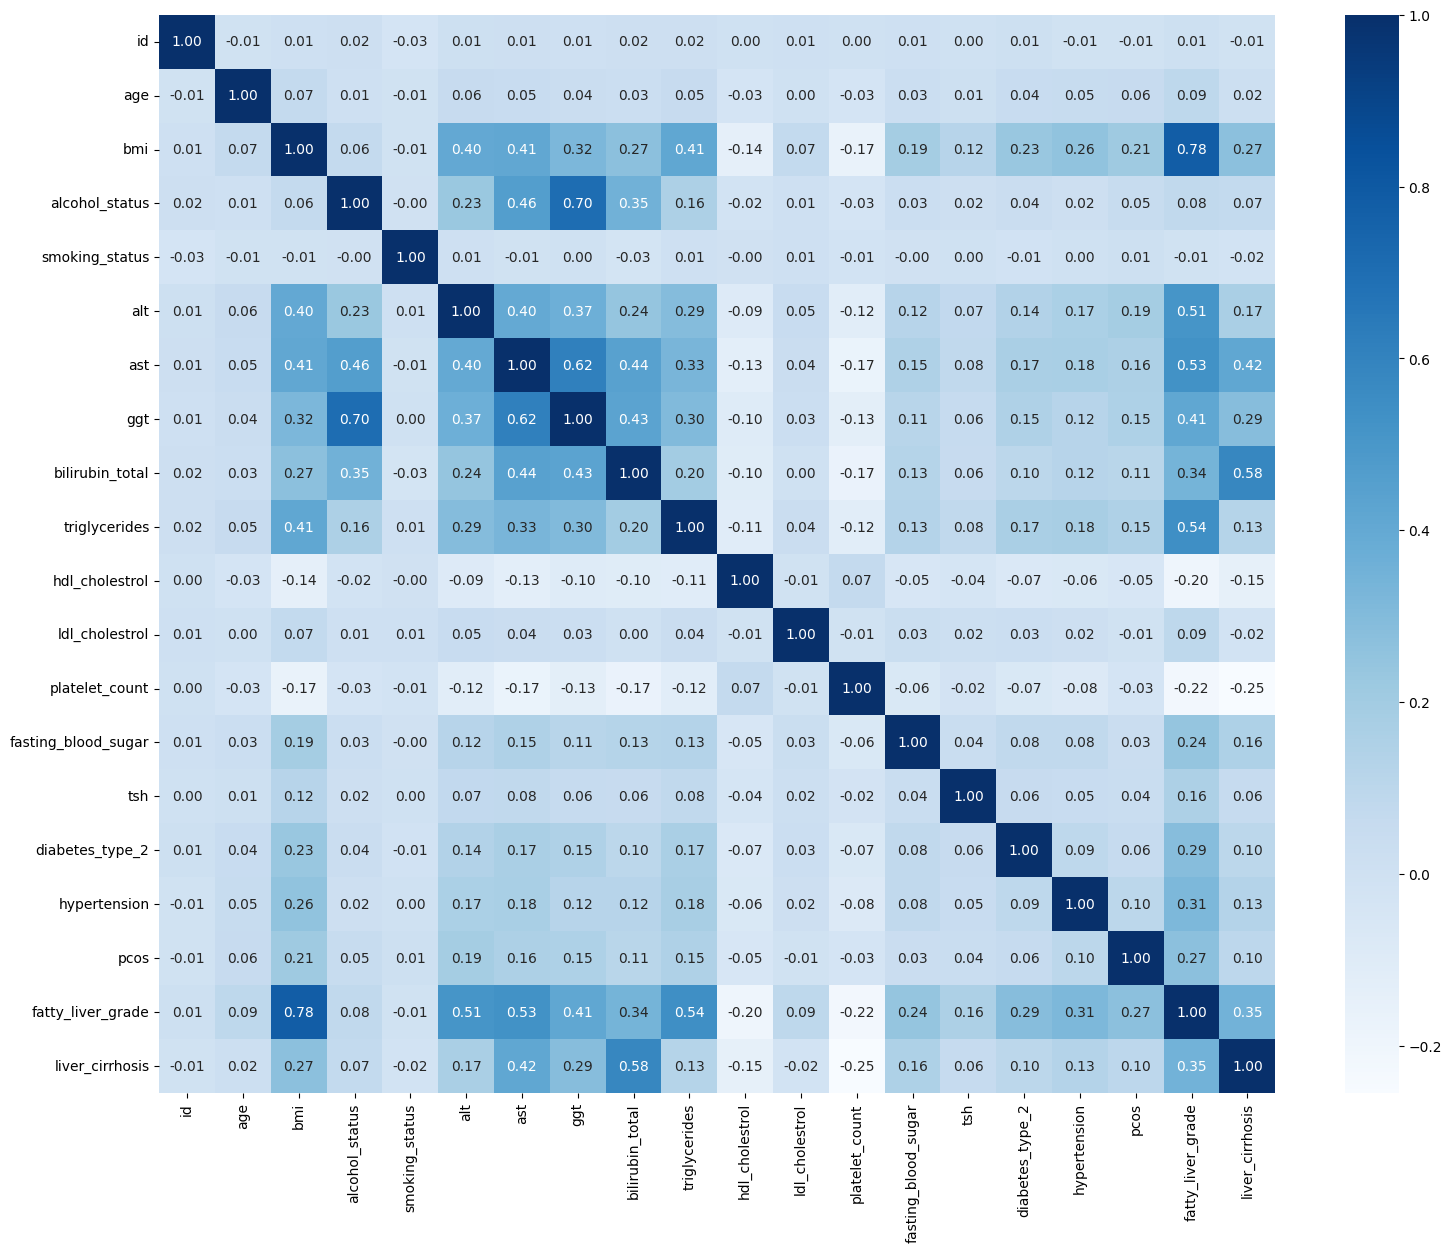

In [93]:
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            fmt='.2f',
            cmap='Blues')
plt.savefig(f'{VISUALISASI}/korelasi.png')
plt.show()

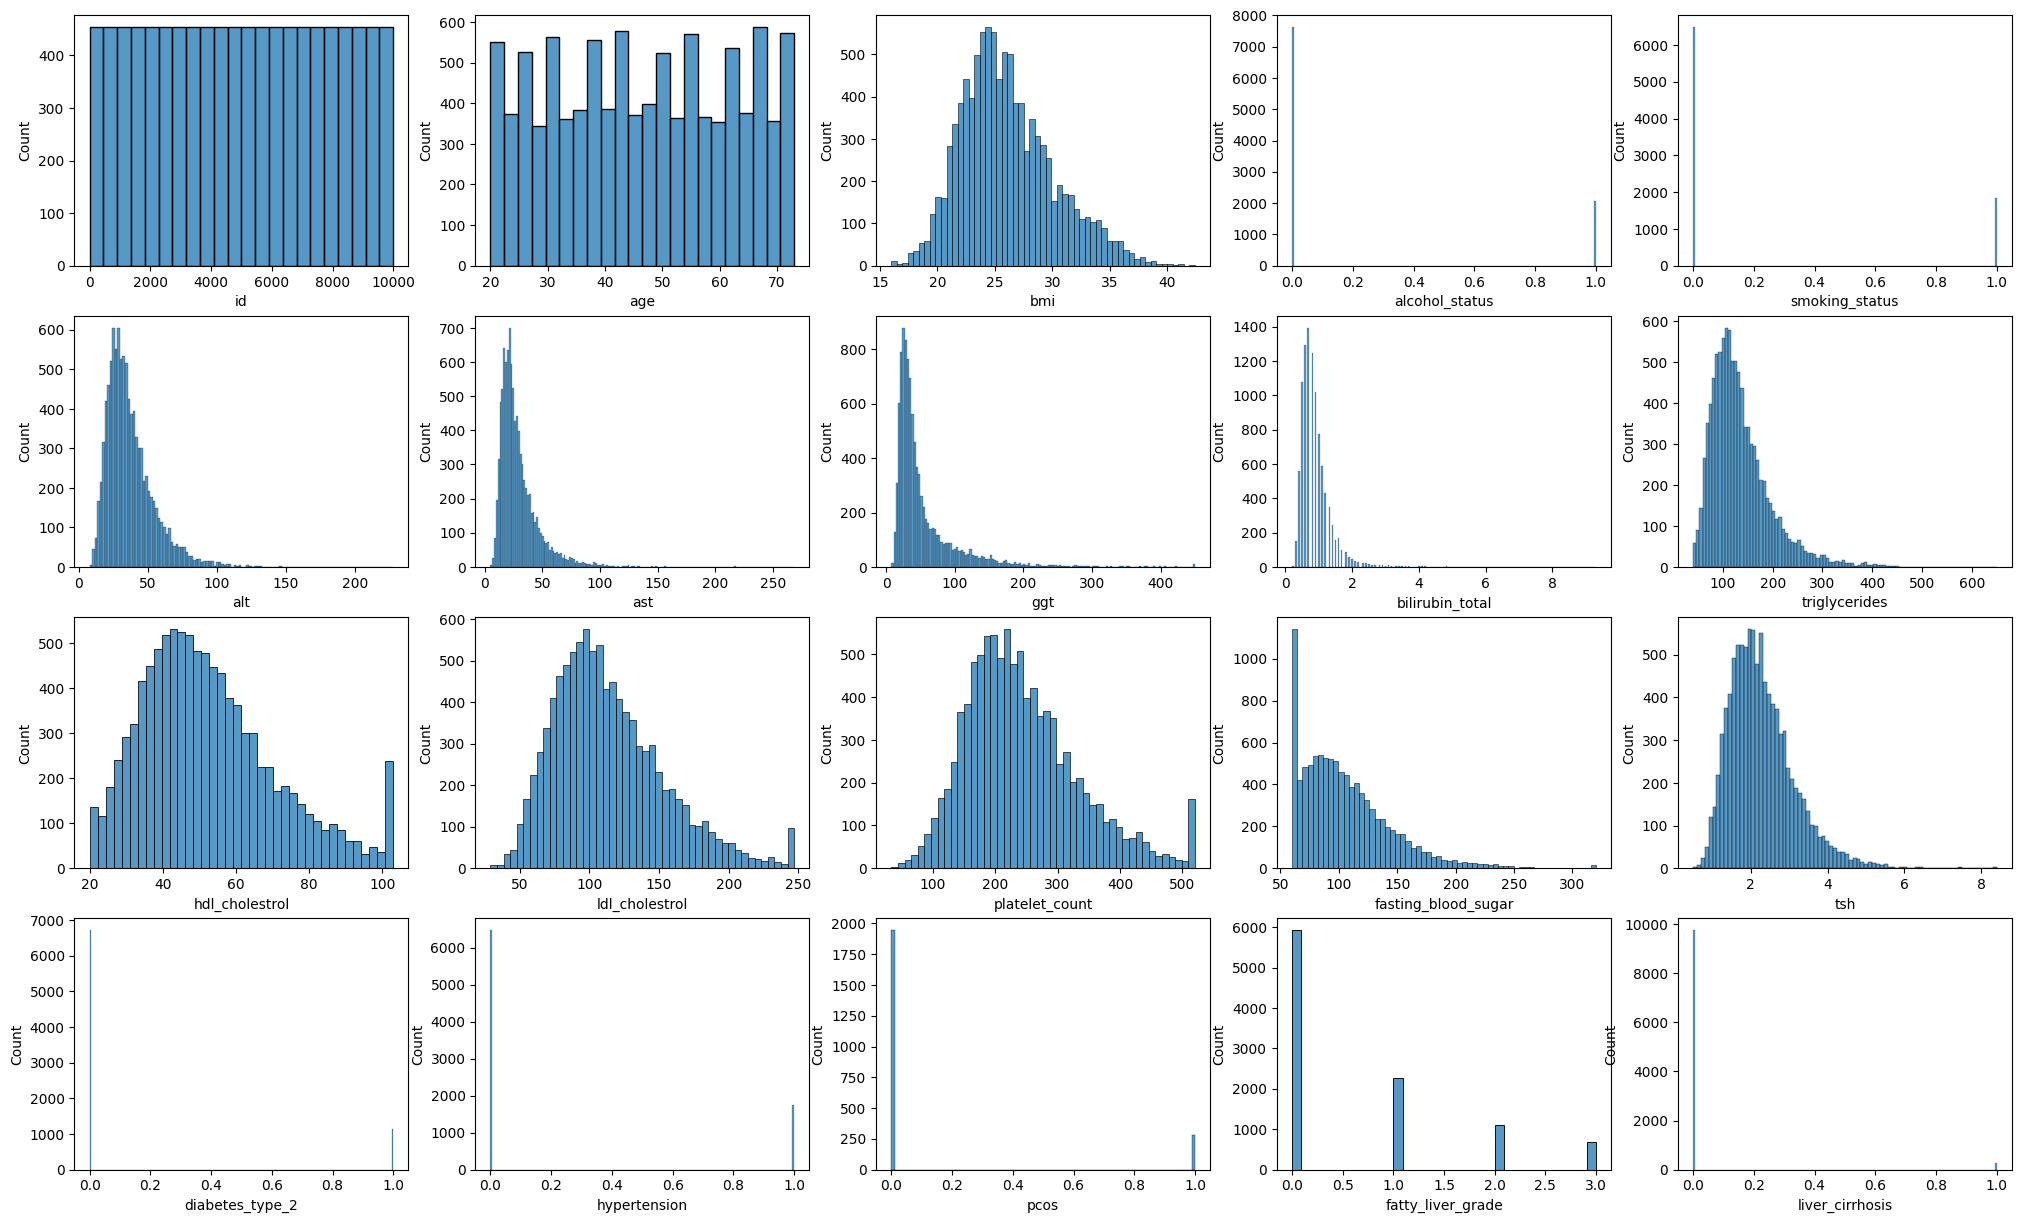

In [94]:
numerical_cols = df.select_dtypes(include=['number']).columns
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(25, 15))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
  sns.histplot(df[col], ax=axes[i])
plt.savefig(f'{VISUALISASI}/histogram.png')
plt.show()

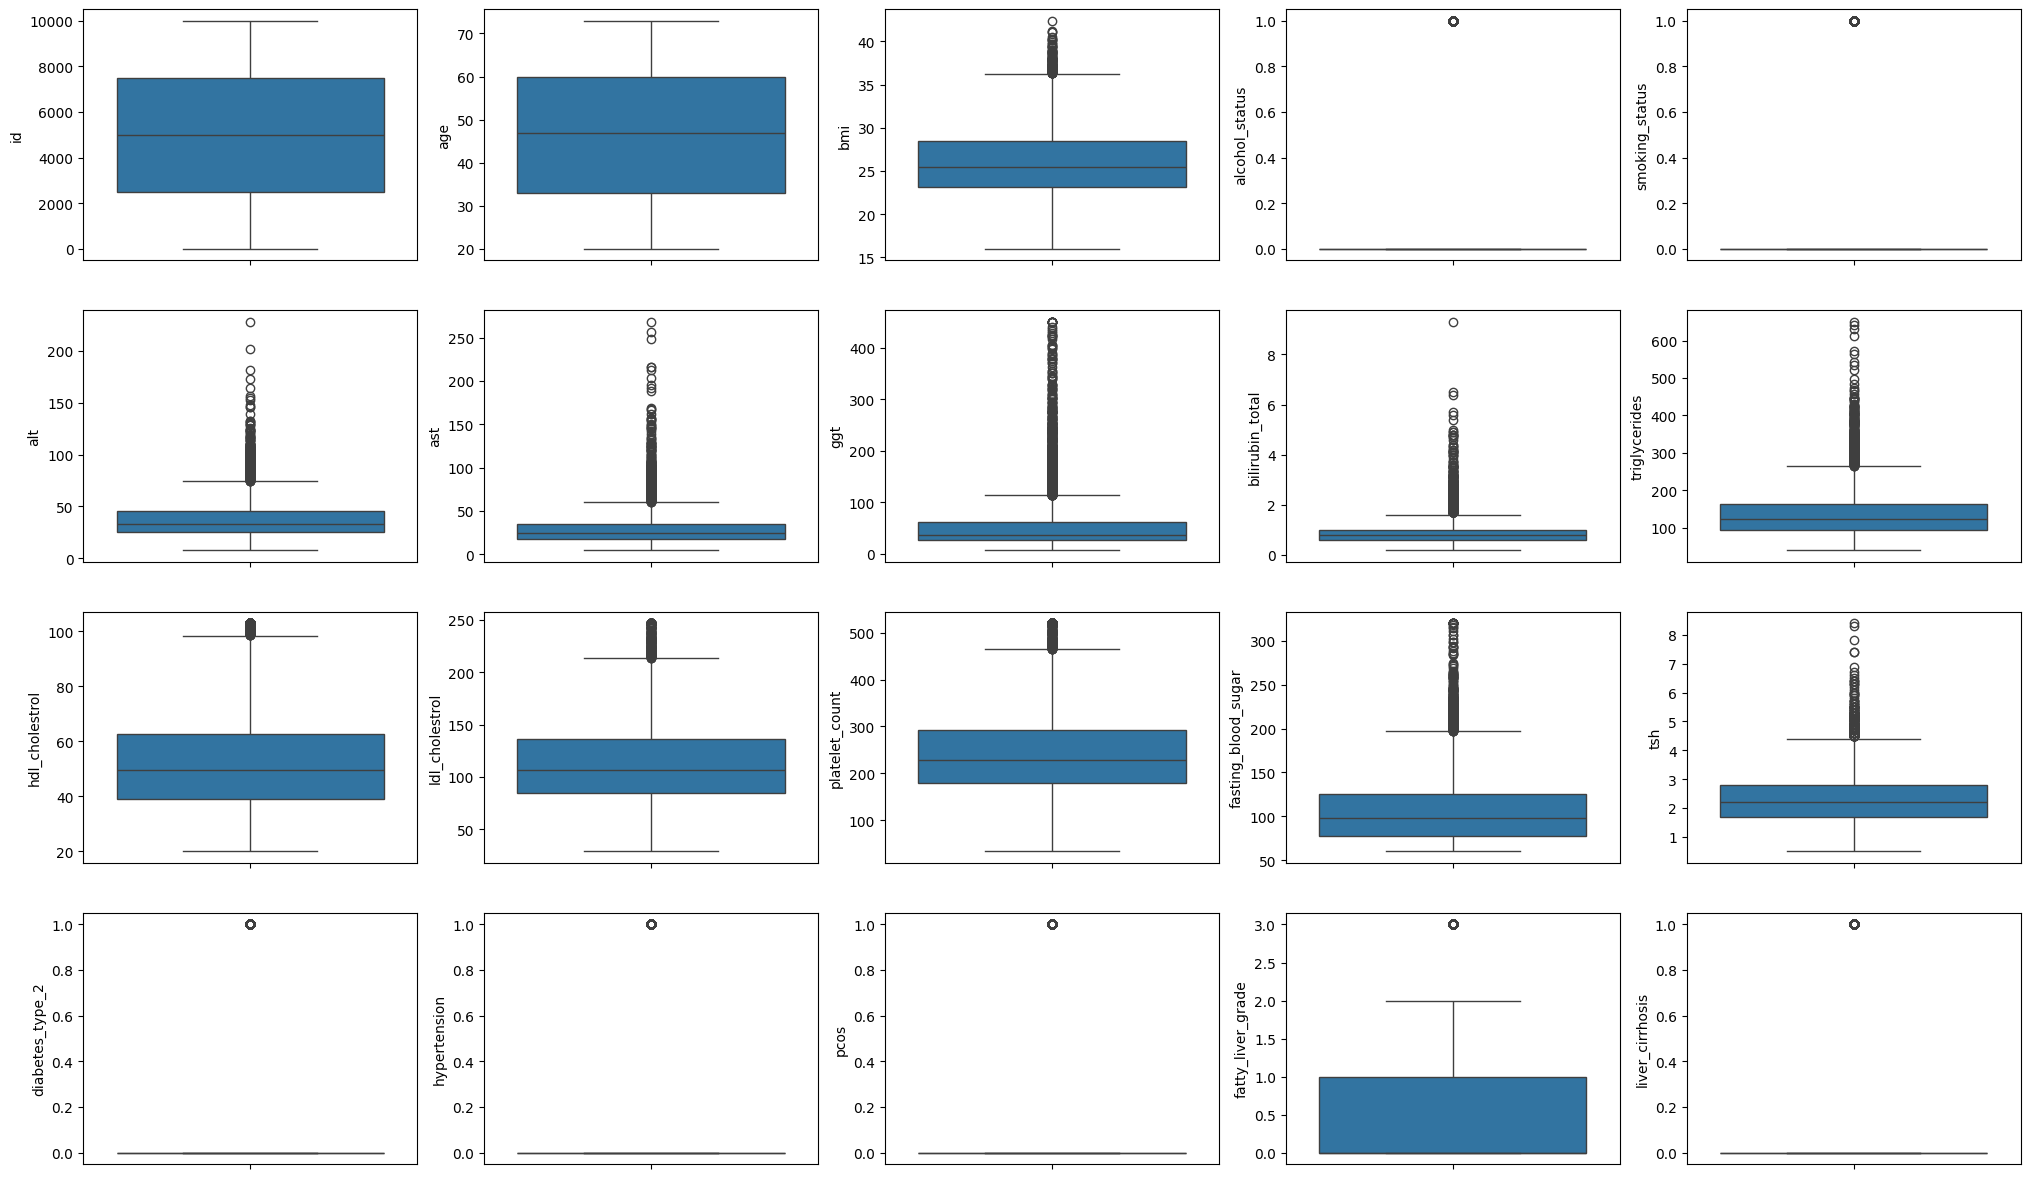

  id: 0 outliers
  age: 0 outliers
  bmi: 131 outliers
  alcohol_status: 2062 outliers
  smoking_status: 1834 outliers
  alt: 389 outliers
  ast: 577 outliers
  ggt: 978 outliers
  bilirubin_total: 543 outliers
  triglycerides: 400 outliers
  hdl_cholestrol: 278 outliers
  ldl_cholestrol: 219 outliers
  platelet_count: 267 outliers
  fasting_blood_sugar: 303 outliers
  tsh: 208 outliers
  diabetes_type_2: 1139 outliers
  hypertension: 1745 outliers
  pcos: 284 outliers
  fatty_liver_grade: 685 outliers
  liver_cirrhosis: 252 outliers


In [95]:
numerical_cols = df.select_dtypes(include=['number']).columns
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(25, 15))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
  sns.boxplot(df[col], ax=axes[i])
plt.savefig(f'{VISUALISASI}/boxplot.png')
plt.show()
for col in numerical_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()
    print(f"  {col}: {outliers} outliers")

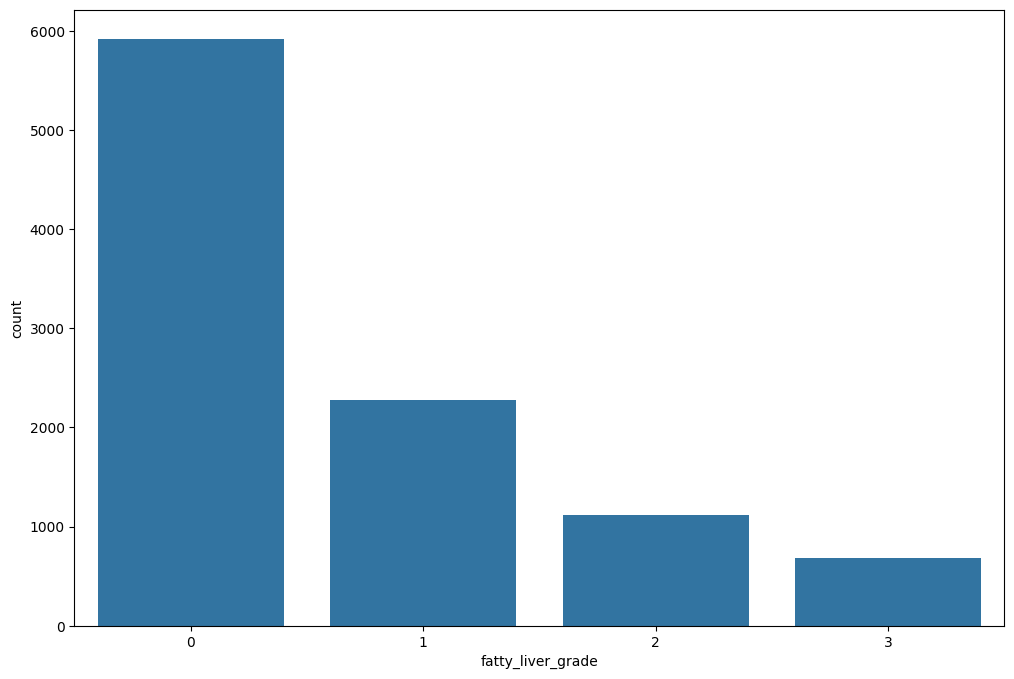

fatty_liver_grade
0    5922
1    2280
2    1113
3     685
Name: count, dtype: int64

In [96]:
plt.figure(figsize=(12, 8))
sns.countplot(x='fatty_liver_grade', data=df)
plt.savefig(f'{VISUALISASI}/countplot.png')
plt.show()
df['fatty_liver_grade'].value_counts()

## `Data Preprocessing / Transformation`

In [97]:
df.isnull().sum()

id                        0
age                       0
gender                    0
bmi                       0
alcohol_status          296
smoking_status         1666
alt                       0
ast                       0
ggt                       0
bilirubin_total           0
triglycerides             0
hdl_cholestrol            0
ldl_cholestrol            0
platelet_count            0
fasting_blood_sugar       0
tsh                       0
diabetes_type_2        2150
hypertension           1790
pcos                   7773
fatty_liver_grade         0
liver_cirrhosis           0
dtype: int64

#### `MENGISI MISSING HIDDEN DENGAN MEAN`

In [98]:
cols = ['alcohol_status','smoking_status','diabetes_type_2','hypertension']

df[cols] = df[cols].fillna(df[cols].mode().iloc[0])

df.drop(columns=['pcos'], inplace=True)

## `Feature Engineering`

In [99]:
X = df.drop(columns=['fatty_liver_grade'])
y = df['fatty_liver_grade']

#### `ENCODING`

In [100]:
numeric_cols = X.select_dtypes(include=['int64','float64']).columns
categorical_cols = X.select_dtypes(include=['object']).columns

preprocessing = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

## `SPLITTING MEMBAGI DATA TRAINING DAN TESTING`

In [101]:
y_binary = df['fatty_liver_grade'].apply(lambda x: 0 if x == 0 else 1)


In [102]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

## `Building the ML Model`

#### `MEMBANGUN MODEL DECISION TREE`

In [103]:
model = Pipeline(
    steps=[
        ('preprocessing', preprocessing),
        ('rf', RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            class_weight='balanced',
            random_state=42
        ))
    ]
)

In [104]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['id', 'age', 'bmi', 'alcohol_status', 'smoking_status', 'alt', 'ast',
       'ggt', 'bilirubin_total', 'triglycerides', 'hdl_cholestrol',
       'ldl_cholestrol', 'platelet_count', 'fasting_blood_sugar', 'tsh',
       'diabetes_type_2', 'hypertension', 'liver_cirrhosis'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender'], dtype='object'))])),
                ('rf',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        n_estimators=300, random_state=42))])

In [105]:
# prediction probabilities

y_prob = model.predict_proba(X_test)[:,1]


for t in [0.3, 0.4, 0.5, 0.6]:
    y_pred = (y_prob > t).astype(int)
    print(f"\nThreshold: {t}")
    print(classification_report(y_test, y_pred))


Threshold: 0.3
              precision    recall  f1-score   support

           0       0.93      0.77      0.84      1184
           1       0.73      0.91      0.81       816

    accuracy                           0.83      2000
   macro avg       0.83      0.84      0.83      2000
weighted avg       0.85      0.83      0.83      2000


Threshold: 0.4
              precision    recall  f1-score   support

           0       0.89      0.86      0.88      1184
           1       0.80      0.85      0.83       816

    accuracy                           0.86      2000
   macro avg       0.85      0.86      0.85      2000
weighted avg       0.86      0.86      0.86      2000


Threshold: 0.5
              precision    recall  f1-score   support

           0       0.87      0.91      0.89      1184
           1       0.86      0.81      0.83       816

    accuracy                           0.87      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.87   

## `EVALUATION MODEL`

#### `CLASSIFICATION REPORT DAN ACCURACY SCORE`

In [106]:
print(classification_report(y_pred, y_test, zero_division=0))
print(accuracy_score(y_pred, y_test))

              precision    recall  f1-score   support

           0       0.95      0.84      0.89      1339
           1       0.74      0.91      0.82       661

    accuracy                           0.86      2000
   macro avg       0.84      0.88      0.85      2000
weighted avg       0.88      0.86      0.87      2000

0.8645


#### `CROSS VALIDATION SCORE`

In [107]:
cv_scores = cross_val_score(model, X, y, cv=2)
print(f"\nCross-Validation Scores (2-fold): {cv_scores}")
print(f"Mean CV Score: {cv_scores.mean():.2%} (+/- {cv_scores.std():.3f})")


Cross-Validation Scores (2-fold): [0.7836 0.755 ]
Mean CV Score: 76.93% (+/- 0.014)


#### `CONFUSION MATRIX`

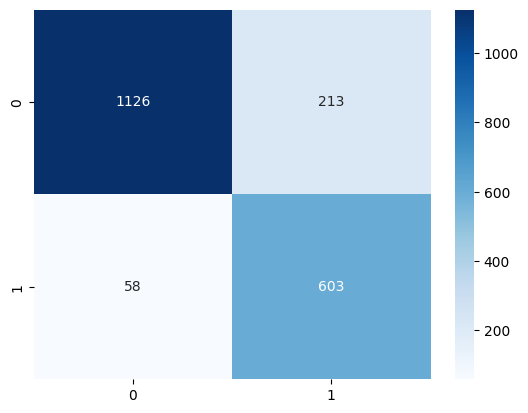

In [108]:
cm = confusion_matrix(y_pred, y_test)
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')
plt.savefig(f'{VISUALISASI}/confusion_matrix.png')
plt.show()

In [109]:
from sklearn.tree import DecisionTreeClassifier
import joblib

joblib.dump(model, "RandomForestClassifier_model.pkl")

['RandomForestClassifier_model.pkl']

In [110]:
from IPython.display import FileLink
FileLink("RandomForestClassifier_model.pkl")

/kaggle/working/RandomForestClassifier_model.pkl